

## **FEATURE ENGINEERING**



In [ ]:
!pip install --upgrade git+https://github.com/ariaghora/mpstemmer.git
!pip install Levenshtein

  Cloning https://github.com/ariaghora/mpstemmer.git to /tmp/pip-req-build-3xz1imh2
  Running command git clone --filter=blob:none --quiet https://github.com/ariaghora/mpstemmer.git /tmp/pip-req-build-3xz1imh2
  Resolved https://github.com/ariaghora/mpstemmer.git to commit 25a5fd923af163a7eac3a5ec976984156ca8fa8b
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import nltk
from nltk.corpus import stopwords
nltk.download('stopwords')
sw = set(stopwords.words('indonesian'))

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [ ]:
import requests
from bs4 import BeautifulSoup
import re
import string
from mpstemmer import MPStemmer
stemmer = MPStemmer()

def scrape_detik_article(base_url, max_pages=5):
    headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64)"}
    all_text = []

    for page in range(1, max_pages + 1):
        url = base_url if page == 1 else f"{base_url}?page={page}"
        response = requests.get(url, headers=headers)
        if response.status_code != 200:
            break

        soup = BeautifulSoup(response.text, 'html.parser')
        body = soup.find('div', class_='detail__body-text itp_bodycontent')
        if not body:
            break

        paragraphs = body.find_all('p')
        page_text = ' '.join(
            p.get_text().strip() for p in paragraphs
            if 'para_caption' not in p.get('class', [])
        )
        all_text.append(page_text)

        pagination_text = soup.get_text()
        if f"Halaman {page} dari {page}" in pagination_text:
            break

    return ' '.join(all_text)

# ambil langsung dari web
url = "https://news.detik.com/berita/d-8675026/misi-paket-vape-narkoba-berujung-jule-direhabilitasi"
teks_artikel_asli = scrape_detik_article(url)

print(teks_artikel_asli)
print(f"\nJumlah karakter: {len(teks_artikel_asli)}")

def remove_duplicate_text(text):
    n = len(text)
    half = n // 2
    if text[:half].strip() == text[half:].strip():
        return text[:half].strip()
    return text

teks_artikel_asli = remove_duplicate_text(teks_artikel_asli)
print(f"Jumlah karakter setelah menghapus duplikat: {len(teks_artikel_asli)}")

sentences_raw = re.split(r'(?<=[.!?])\s+', teks_artikel_asli.strip())

def preprocess(text):
    text = text.lower()
    text = text.translate(str.maketrans('', '', string.punctuation))
    text = re.sub(r'\s+', ' ', text).strip()
    text = stemmer.stem_kalimat(text)  # MPStemmer
    text = " ".join([w for w in text.split() if w not in sw])  # stopwords
    return text

docs = [preprocess(s) for s in sentences_raw]
docs = [d for d in docs if d.strip() != '']
print(f"Jumlah dokumen (kalimat): {len(docs)}")

sentences_tokenized = [d.split() for d in docs]
print(sentences_tokenized[:3])  # cek 3 contoh pertama

Selebgram Julia Prastini atau Jule ditangkap terkait kasus vape narkoba. Dia mendapatkan rehabilitasi setelah kedapatan positif mengonsumsi vape narkoba. Jule ditangkap di sebuah apartemen di Cilandak, Jakarta Selatan (Jaksel), pada Senin (14/9/2026). Ia diamankan saat hendak menerima paket vape narkoba. Dalam penangkapan tersebut, polisi menyita paket berisi 1 catridge vape narkoba dan tiga vape lainnya dalam keadaan kosong sisa pakai. Jule mengaku mengonsumsi narkoba karena stress. Pengungkapan kasus bermula saat anggota Satresnarkoba Polresta Bandara Soekarno-Hatta mengamankan dua wanita berinisial RR dan RN di sebuah apartemen di kawasan Kembangan, Jakarta Barat, pada Senin (14/9/2026) sekitar pukul 13.00 WIB. "Dari lokasi tersebut, petugas menemukan 27 cartridge vape yang diduga mengandung etomidate," ujar Kabid Humas Polda Metro Jaya Kombes Budi Hermanto dalam keterangannya kepada wartawan, Sabtu (19/9). Dari pengungkapan terhadap RR dan RN, polisi kemudian mengamankan pria asal 

**Bag of Word**

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd

vectorizer_bow = CountVectorizer()  # tanpa binary=True -> ini hitung frekuensi, bukan cuma ada/tidak
X_bow = vectorizer_bow.fit_transform(docs)
df_bow = pd.DataFrame(X_bow.toarray(), columns=vectorizer_bow.get_feature_names_out())
print("Shape BoW:", df_bow.shape)
df_bow

Shape BoW: (33, 136)


,1300,1492026,199,20detik,229,2292026,27,99,akp,alas,...,terang,terima,tim,utara,vape,video,wanita,wartawan,wib,xc
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0
2,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,1,0,0,1,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,2,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
6,1,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,1,0
7,0,0,1,0,0,0,1,0,0,0,...,1,0,0,0,1,0,0,1,0,0
8,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
9,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,1,0,0,0,0,0


**One Hot Encoding**

In [ ]:
vectorizer_ohe = CountVectorizer(binary=True)
X_ohe = vectorizer_ohe.fit_transform(docs)
df_ohe = pd.DataFrame(X_ohe.toarray(), columns=vectorizer_ohe.get_feature_names_out())
print("Shape One-Hot:", df_ohe.shape)
df_ohe

Shape One-Hot: (33, 136)


,1300,1492026,199,20detik,229,2292026,27,99,akp,alas,...,terang,terima,tim,utara,vape,video,wanita,wartawan,wib,xc
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0
2,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,1,0,0,1,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
6,1,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,1,0
7,0,0,1,0,0,0,1,0,0,0,...,1,0,0,0,1,0,0,1,0,0
8,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
9,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,1,0,0,0,0,0


**TF IDF**

In [ ]:
#TF-IDF

from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer_tfidf = TfidfVectorizer()
X_tfidf = vectorizer_tfidf.fit_transform(docs)
df_tfidf = pd.DataFrame(X_tfidf.toarray(), columns=vectorizer_tfidf.get_feature_names_out())
print("Shape TF-IDF:", df_tfidf.shape)

print("\nTop 10 kata dengan skor TF-IDF rata-rata tertinggi:")
print(df_tfidf.mean(axis=0).sort_values(ascending=False).head(10))

Shape TF-IDF: (33, 136)

Top 10 kata dengan skor TF-IDF rata-rata tertinggi:
jule            0.120894
menarkoba       0.091705
vape            0.085686
pakai           0.080772
rehabilitasi    0.072571
jp              0.065424
asesmen         0.059078
periksa         0.055513
konsumsi        0.054271
polisi          0.052477
dtype: float64


**Word2vec**

In [ ]:
!pip install gensim
import gensim.models

model_w2v = gensim.models.Word2Vec(sentences_tokenized, vector_size=50, window=5, min_count=1, workers=4)
w2v = model_w2v.wv

print("Jumlah vocabulary:", len(w2v.index_to_key))
for word in ['jule', 'narkoba', 'vape', 'polisi']:
    if word in w2v:
        print(f"\nKata paling mirip dengan '{word}':")
        print(w2v.similar_by_key(word, topn=5))

Jumlah vocabulary: 138

Kata paling mirip dengan 'jule':
[('terima', 0.32559913396835327), ('jaring', 0.27275052666664124), ('sabtu', 0.27228018641471863), ('konsumsi', 0.2720145285129547), ('penyidik', 0.25569960474967957)]

Kata paling mirip dengan 'narkoba':
[('1492026', 0.30427053570747375), ('jp', 0.2940376102924347), ('hubung', 0.2791203558444977), ('komunikasi', 0.2676681876182556), ('saksi', 0.24823498725891113)]

Kata paling mirip dengan 'vape':
[('buah', 0.34271568059921265), ('paket', 0.3283090591430664), ('kharisma', 0.2917182445526123), ('prastin', 0.26536521315574646), ('kembang', 0.255998820066452)]

Kata paling mirip dengan 'polisi':
[('1492026', 0.3248099386692047), ('sisa', 0.28512564301490784), ('rr', 0.258049875497818), ('prastini', 0.2394075095653534), ('budi', 0.23682798445224762)]


In [ ]:
!pip install umap-learn[plot]
!pip install holoviews
!pip install -U ipykernel

In [ ]:
from umap import UMAP
import plotly.express as px
import pandas as pd
import numpy as np

In [ ]:
# Word2vec Visualization

X = UMAP().fit_transform(w2v.vectors)

df2 = pd.DataFrame(X, columns=['umap1', 'umap2'])
df2['word'] = w2v.index_to_key

fig = px.scatter(df2, x='umap1', y='umap2', text='word')
fig.update_traces(textposition='top center')
fig.update_layout(height=800, title_text='Word2Vec Visualization')
fig.show()

**FastText**

In [ ]:
model_ft = gensim.models.FastText(sentences_tokenized, vector_size=50, window=5, min_count=1, workers=4)
ft = model_ft.wv

print("Jumlah vocabulary:", len(ft.index_to_key))
for word in ['jule', 'narkoba', 'vape', 'polisi']:
    print(f"\nKata paling mirip dengan '{word}' (FastText):")
    print(ft.similar_by_key(word, topn=5))

Jumlah vocabulary: 138

Kata paling mirip dengan 'jule' (FastText):
[('julia', 0.43302133679389954), ('dasar', 0.36141979694366455), ('bandara', 0.3479076325893402), ('1', 0.3131549060344696), ('catridge', 0.27803677320480347)]

Kata paling mirip dengan 'narkoba' (FastText):
[('menarkoba', 0.627864420413971), ('satresnarkoba', 0.4431687295436859), ('rangkai', 0.40213754773139954), ('etomidate', 0.39513033628463745), ('narkotika', 0.3566195070743561)]

Kata paling mirip dengan 'vape' (FastText):
[('1300', 0.24656572937965393), ('terang', 0.2431277185678482), ('petugas', 0.2243337333202362), ('minggu', 0.21239089965820312), ('positif', 0.2082924097776413)]

Kata paling mirip dengan 'polisi' (FastText):
[('jp', 0.4311685264110565), ('kombes', 0.3645375967025757), ('isi', 0.34381383657455444), ('catridge', 0.3040369153022766), ('kosong', 0.2897456884384155)]


In [ ]:
X = UMAP().fit_transform(ft.vectors)

df2 = pd.DataFrame(X, columns=['umap1', 'umap2'])
df2['word'] = ft.index_to_key

fig = px.scatter(df2, x='umap1', y='umap2', text='word')
fig.update_traces(textposition='top center')
fig.update_layout(height=800, title_text='FastText Visualization')
fig.show()

In [ ]:
teks_artikel_asli = """Selebgram Julia Prastini atau Jule ditangkap terkait kasus vape narkoba. Dia mendapatkan rehabilitasi setelah kedapatan positif mengonsumsi vape narkoba. Jule ditangkap di sebuah apartemen di Cilandak, Jakarta Selatan (Jaksel), pada Senin (14/9/2026). Ia diamankan saat hendak menerima paket vape narkoba. Dalam penangkapan tersebut, polisi menyita paket berisi 1 catridge vape narkoba dan tiga vape lainnya dalam keadaan kosong sisa pakai. Jule mengaku mengonsumsi narkoba karena stress. Pengungkapan kasus bermula saat anggota Satresnarkoba Polresta Bandara Soekarno-Hatta mengamankan dua wanita berinisial RR dan RN di sebuah apartemen di kawasan Kembangan, Jakarta Barat, pada Senin (14/9/2026) sekitar pukul 13.00 WIB. "Dari lokasi tersebut, petugas menemukan 27 cartridge vape yang diduga mengandung etomidate," ujar Kabid Humas Polda Metro Jaya Kombes Budi Hermanto dalam keterangannya kepada wartawan, Sabtu (19/9). Dari pengungkapan terhadap RR dan RN, polisi kemudian mengamankan pria asal China inisial XC. Dari ketiganya itu polisi menyita 99 catridge vape narkoba. RR, RN, dan XC telah ditetapkan sebagai tersangka. Sementara Jule dikategorikan sebagai pemakai dan direhabilitasi.  Selebgram Julia Prastini (JP) alias Jule ditangkap Satresnarkoba Polresta Bandara Soekarno-Hatta (Soetta) terkait kasus narkoba. Jule akan direhabilitasi. "JP selanjutnya menjalani asesmen oleh Tim Asesmen Terpadu BNNP DKI Jakarta. Berdasarkan hasil asesmen tersebut, JP juga dinyatakan sebagai pengguna atau pemakai narkotika dan direkomendasikan untuk menjalani rehabilitasi sesuai hasil asesmen," ujar Kabid Humas Polda Metro Jaya Kombes Budi Hermanto saat dihubungi wartawan, Selasa (22/9). Dia mengatakan, berdasarkan hasil pemeriksaan saksi dan barang bukti, Jule tidak terbukti dalam peredaran narkotika. Karena itu, Jule dikategorikan sebagai korban atau penyalah guna. "Penyidik tidak menemukan fakta yang mengarah pada keterlibatan JP dalam kegiatan mengedarkan atau menjual narkotika. Dari rangkaian pemeriksaan tersebut, JP diketahui sebagai pengguna atau pemakai," ungkapnya.     Kombes Budi Hermanto mengungkap status Jule dalam perkara tersebut. Dia menyebut bahwa Jule tak ada kaitan dengan jaringan pengedar. "Berdasarkan hasil pemeriksaan terhadap JP, keterangan para saksi, pendalaman riwayat komunikasi, jumlah barang bukti, serta alat bukti lainnya, penyidik tidak menemukan fakta yang mengarah pada keterlibatan JP dalam kegiatan mengedarkan atau menjual narkotika," ujar Kabid Humas Polda Metro Jaya Kombes Budi Hermanto saat dihubungi wartawan, Selasa (22/9/2026). Kombes Budi menyampaikan, dari hasil pemeriksaan, Jule diketahui sebagai pengguna atau pemakai. Karena itu, Jule dilakukan asesmen untuk menjalani rehabilitasi. "Dari rangkaian pemeriksaan tersebut, JP diketahui sebagai pengguna atau pemakai. JP selanjutnya menjalani asesmen oleh Tim Asesmen Terpadu BNNP DKI Jakarta," ungkapnya.   Kepada polisi, Jule mengaku baru 3 mingguan mencoba vape narkoba. Dia berlasan mengonsumsi vape narkoba karena stress. "Alasannya pribadi mungkin dari rasa ada stres dan lain sebagainya atau alasan yang diutarakan oleh JP," ujar Kasat Narkoba Polres Bandara Soekarno-Hatta, AKP Michael Kharisma Tandayu, Sabtu (19/9). Jule diduga sudah beberapa kali mengonsumsi vape narkoba. Polisi menyebut Jule sudah 3 minggu pakai narkoba.  Simak juga Video 'Dalih Klasik Jule Pakai Vape Narkoba':  [Gambas:Video 20detik]   Selebgram Julia Prastini atau Jule ditangkap terkait kasus vape narkoba. Dia mendapatkan rehabilitasi setelah kedapatan positif mengonsumsi vape narkoba. Jule ditangkap di sebuah apartemen di Cilandak, Jakarta Selatan (Jaksel), pada Senin (14/9/2026). Ia diamankan saat hendak menerima paket vape narkoba. Dalam penangkapan tersebut, polisi menyita paket berisi 1 catridge vape narkoba dan tiga vape lainnya dalam keadaan kosong sisa pakai. Jule mengaku mengonsumsi narkoba karena stress. Pengungkapan kasus bermula saat anggota Satresnarkoba Polresta Bandara Soekarno-Hatta mengamankan dua wanita berinisial RR dan RN di sebuah apartemen di kawasan Kembangan, Jakarta Barat, pada Senin (14/9/2026) sekitar pukul 13.00 WIB. "Dari lokasi tersebut, petugas menemukan 27 cartridge vape yang diduga mengandung etomidate," ujar Kabid Humas Polda Metro Jaya Kombes Budi Hermanto dalam keterangannya kepada wartawan, Sabtu (19/9). Dari pengungkapan terhadap RR dan RN, polisi kemudian mengamankan pria asal China inisial XC. Dari ketiganya itu polisi menyita 99 catridge vape narkoba. RR, RN, dan XC telah ditetapkan sebagai tersangka. Sementara Jule dikategorikan sebagai pemakai dan direhabilitasi.  Selebgram Julia Prastini (JP) alias Jule ditangkap Satresnarkoba Polresta Bandara Soekarno-Hatta (Soetta) terkait kasus narkoba. Jule akan direhabilitasi. "JP selanjutnya menjalani asesmen oleh Tim Asesmen Terpadu BNNP DKI Jakarta. Berdasarkan hasil asesmen tersebut, JP juga dinyatakan sebagai pengguna atau pemakai narkotika dan direkomendasikan untuk menjalani rehabilitasi sesuai hasil asesmen," ujar Kabid Humas Polda Metro Jaya Kombes Budi Hermanto saat dihubungi wartawan, Selasa (22/9). Dia mengatakan, berdasarkan hasil pemeriksaan saksi dan barang bukti, Jule tidak terbukti dalam peredaran narkotika. Karena itu, Jule dikategorikan sebagai korban atau penyalah guna. "Penyidik tidak menemukan fakta yang mengarah pada keterlibatan JP dalam kegiatan mengedarkan atau menjual narkotika. Dari rangkaian pemeriksaan tersebut, JP diketahui sebagai pengguna atau pemakai," ungkapnya.     Kombes Budi Hermanto mengungkap status Jule dalam perkara tersebut. Dia menyebut bahwa Jule tak ada kaitan dengan jaringan pengedar. "Berdasarkan hasil pemeriksaan terhadap JP, keterangan para saksi, pendalaman riwayat komunikasi, jumlah barang bukti, serta alat bukti lainnya, penyidik tidak menemukan fakta yang mengarah pada keterlibatan JP dalam kegiatan mengedarkan atau menjual narkotika," ujar Kabid Humas Polda Metro Jaya Kombes Budi Hermanto saat dihubungi wartawan, Selasa (22/9/2026). Kombes Budi menyampaikan, dari hasil pemeriksaan, Jule diketahui sebagai pengguna atau pemakai. Karena itu, Jule dilakukan asesmen untuk menjalani rehabilitasi. "Dari rangkaian pemeriksaan tersebut, JP diketahui sebagai pengguna atau pemakai. JP selanjutnya menjalani asesmen oleh Tim Asesmen Terpadu BNNP DKI Jakarta," ungkapnya.   Kepada polisi, Jule mengaku baru 3 mingguan mencoba vape narkoba. Dia berlasan mengonsumsi vape narkoba karena stress. "Alasannya pribadi mungkin dari rasa ada stres dan lain sebagainya atau alasan yang diutarakan oleh JP," ujar Kasat Narkoba Polres Bandara Soekarno-Hatta, AKP Michael Kharisma Tandayu, Sabtu (19/9). Jule diduga sudah beberapa kali mengonsumsi vape narkoba. Polisi menyebut Jule sudah 3 minggu pakai narkoba.  Simak juga Video 'Dalih Klasik Jule Pakai Vape Narkoba':  [Gambas:Video 20detik]"""

# opsional: buang teks bawaan halaman web (bukan isi berita)
teks_artikel_asli = teks_artikel_asli.replace(
    "Simak juga Video 'Dalih Klasik Jule Pakai Vape Narkoba':  [Gambas:Video 20detik]", "")

print(len(teks_artikel_asli))   # sekitar 3425 kalau belum dibuang bagian opsional

6693


# 2. Text Clustering

Menyiapkan Data

In [ ]:
import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn import metrics
from wordcloud import WordCloud

df = pd.DataFrame({'prepro': docs})   # docs sudah sejajar dengan df_tfidf
df_FE = df_tfidf

## Unsupervised: KMeans

Memakai elbow dan sillhouette untuk memilih k

[1, 2, 3, 4, 5, 6, 7, 8]
[29.684359988077095, 27.57674777870208, 25.859759336760547, 24.600364055525926, 23.20546173591037, 21.78588624595308, 19.877629196141246, 19.30342538782711]


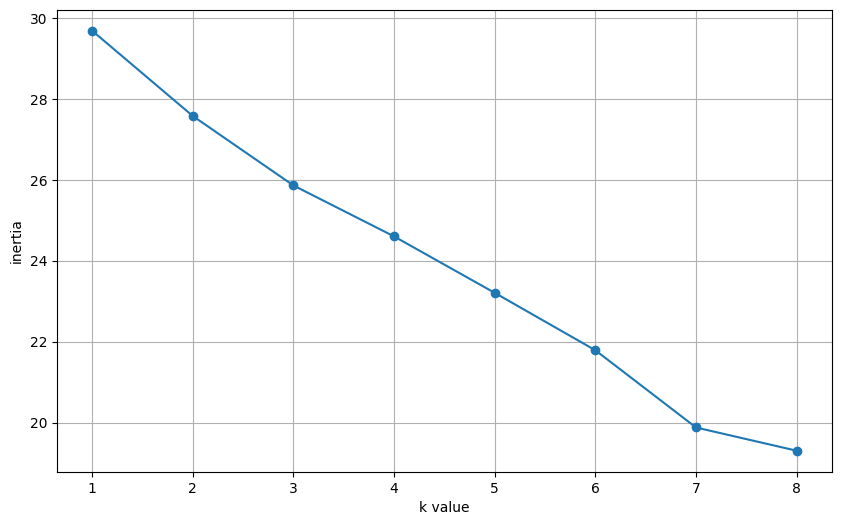

2 0.047001438368864945
3 0.054686982748619446
4 0.04873801237628825
5 0.05550817301036382
6 0.05994219563532483
7 0.08528920618740095
8 0.0600118712564401


In [ ]:
k = range(1, 9)
inertia = []
for i in k:
    km_model = KMeans(n_clusters=i, random_state=10)
    km_model.fit(df_FE)
    inertia.append(km_model.inertia_)

print(list(k))
print(inertia)

plt.figure(figsize=(10,6))
plt.plot(k, inertia, marker='o')
plt.xlabel('k value')
plt.ylabel('inertia')
plt.grid()
plt.show()

for i in range(2, 9):
    lab = KMeans(n_clusters=i, random_state=10).fit(df_FE).labels_
    print(i, metrics.silhouette_score(df_FE, lab, metric='euclidean'))

menentukan n_clusters

In [ ]:
n_clusters = 3

KMeans Final

In [ ]:
kM = KMeans(n_clusters=n_clusters, random_state=10).fit(df_FE)
df['Kmeans_label'] = kM.labels_
print('Silhouette KMeans:', metrics.silhouette_score(df_FE, kM.labels_, metric='euclidean'))
df.head()

Silhouette KMeans: 0.054686982748619446


,prepro,Kmeans_label,Ward_label
0,selebgram julia prastini jule tangkap kait vap...,2,0
1,rehabilitasi positif konsumsi vape menarkoba,2,1
2,jule tangkap buah apartemen cilandak jakarta s...,2,0
3,aman terima paket vape menarkoba,2,1
4,tangkap polisi sita paket isi 1 catridge vape ...,2,1


## Unsupervised: Hierarchical

Dendrogram

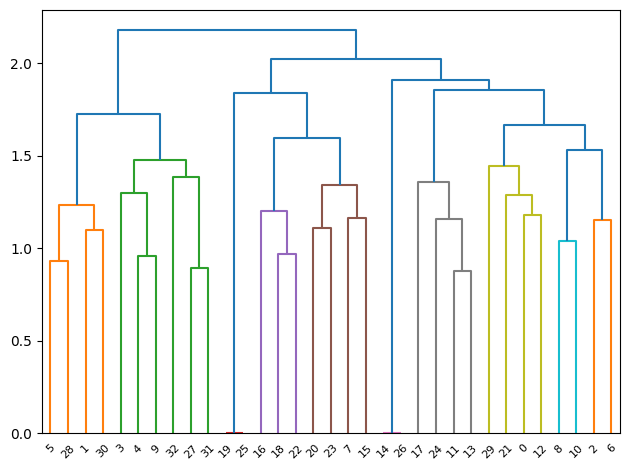

In [ ]:
from scipy.cluster.hierarchy import dendrogram, linkage

linkage_data = linkage(df_FE, method='ward', metric='euclidean')
dendrogram(linkage_data)
plt.tight_layout()
plt.show()

Hierarchical clustering (Agglomerative, linkage Ward)

In [ ]:
hc = AgglomerativeClustering(n_clusters=n_clusters, linkage='ward').fit(df_FE)
df['Ward_label'] = hc.labels_
print('Silhouette Hierarchical:', metrics.silhouette_score(df_FE, hc.labels_, metric='euclidean'))
df.head()

Silhouette Hierarchical: 0.0693838429080469


,prepro,Kmeans_label,Ward_label
0,selebgram julia prastini jule tangkap kait vap...,2,0
1,rehabilitasi positif konsumsi vape menarkoba,2,1
2,jule tangkap buah apartemen cilandak jakarta s...,2,0
3,aman terima paket vape menarkoba,2,1
4,tangkap polisi sita paket isi 1 catridge vape ...,2,1


word cloud KMeans dan Hierarchical

Kmeans for cluster 0


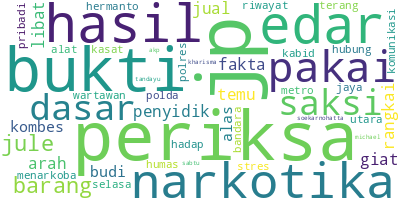

Kmeans for cluster 1


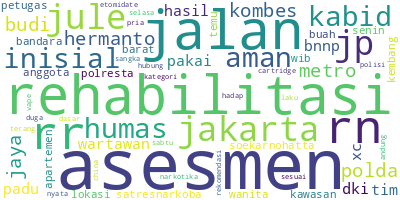

Kmeans for cluster 2


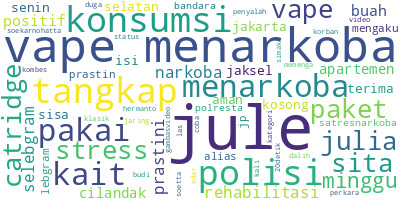

Hierarchical for cluster 0


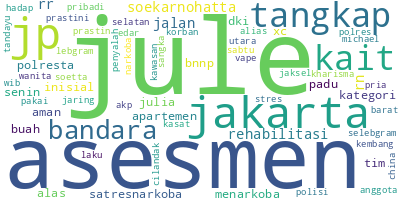

Hierarchical for cluster 1


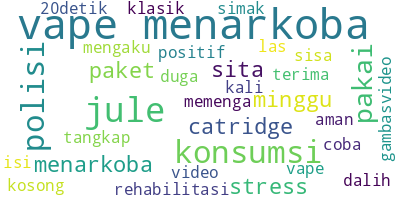

Hierarchical for cluster 2


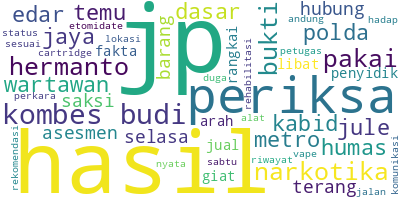

In [ ]:
for col, nama in [('Kmeans_label', 'Kmeans'), ('Ward_label', 'Hierarchical')]:
    for c in range(n_clusters):
        print(nama + ' for cluster ' + str(c))
        long_string = ','.join(df[df[col] == c]['prepro'].values)
        wc = WordCloud(background_color="white", max_words=5000, contour_width=3)
        wc.generate(long_string)
        display(wc.to_image())

isi dan ukuran tiap cluster

In [ ]:
for col in ['Kmeans_label', 'Ward_label']:
    print(col, df[col].value_counts().sort_index().to_dict())
    for c in range(n_clusters):
        print(f'\n[{col} cluster {c}]')
        print(df[df[col] == c]['prepro'].head(3).to_string(index=False))

Kmeans_label {0: 7, 1: 10, 2: 16}

[Kmeans_label cluster 0]
dasar hasil periksa saksi barang bukti jule buk...
penyidik temu fakta arah libat jp giat edar jua...
                          rangkai periksa jp pakai

[Kmeans_label cluster 1]
anggota satresnarkoba polresta bandara soekarno...
lokasi petugas temu 27 cartridge vape duga andu...
     hadap rr rn polisi aman pria china inisial xc

[Kmeans_label cluster 2]
selebgram julia prastini jule tangkap kait vape...
      rehabilitasi positif konsumsi vape menarkoba
jule tangkap buah apartemen cilandak jakarta se...
Ward_label {0: 14, 1: 10, 2: 9}

[Ward_label cluster 0]
selebgram julia prastini jule tangkap kait vape...
jule tangkap buah apartemen cilandak jakarta se...
anggota satresnarkoba polresta bandara soekarno...

[Ward_label cluster 1]
      rehabilitasi positif konsumsi vape menarkoba
                  aman terima paket vape menarkoba
tangkap polisi sita paket isi 1 catridge vape m...

[Ward_label cluster 2]
lokasi petugas temu